In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

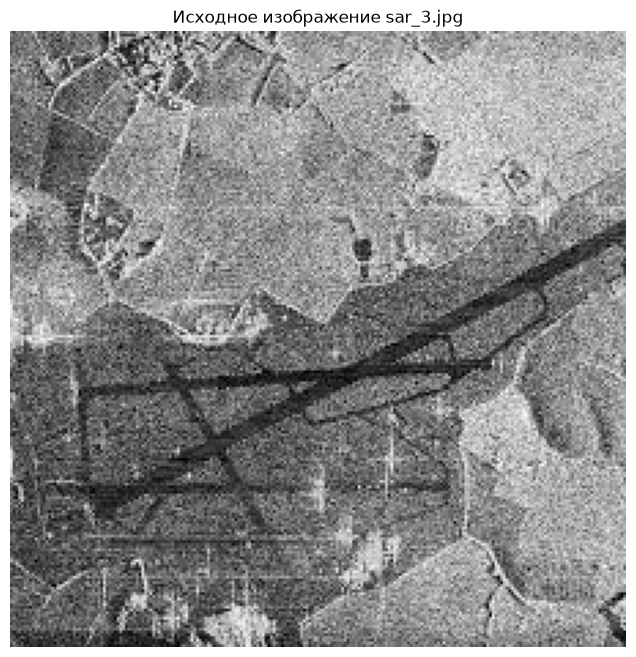

In [2]:
image_sar3 = cv2.imread('sar_3.jpg')
image_sar3_gray = cv2.cvtColor(image_sar3, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 8))
plt.imshow(image_sar3_gray, cmap='gray')
plt.title('Исходное изображение sar_3.jpg')
plt.axis('off')
plt.show()

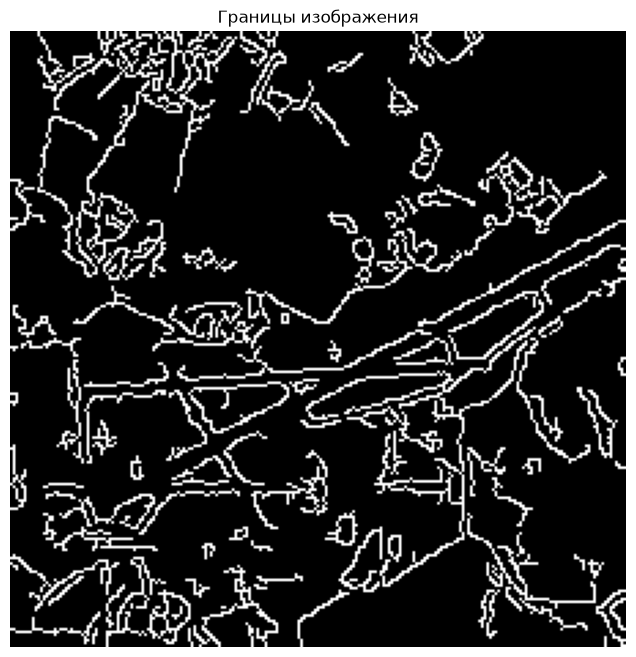

In [3]:
blurred = cv2.GaussianBlur(image_sar3_gray, (5, 5), 0)

edges = cv2.Canny(blurred, 80, 180)

plt.figure(figsize=(8, 8))
plt.imshow(edges, cmap='gray')
plt.title('Границы изображения')
plt.axis('off')
plt.show()

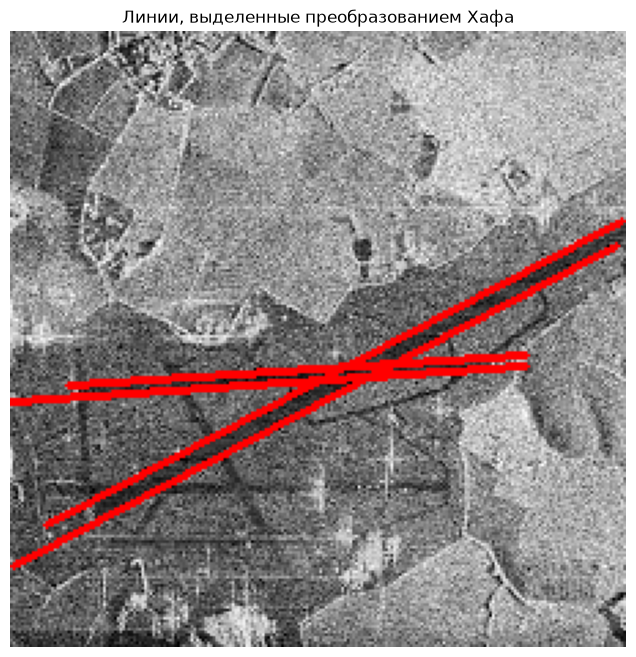

In [4]:
lines = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi / 180,
    threshold=80,
    minLineLength=80,
    maxLineGap=20
)

image_lines = image_sar3.copy()

if lines is not None:
    for line in lines.reshape(-1, 4):
        x1, y1, x2, y2 = line
        cv2.line(image_lines, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(image_lines, cv2.COLOR_BGR2RGB))
plt.title('Линии, выделенные преобразованием Хафа')
plt.axis('off')
plt.show()

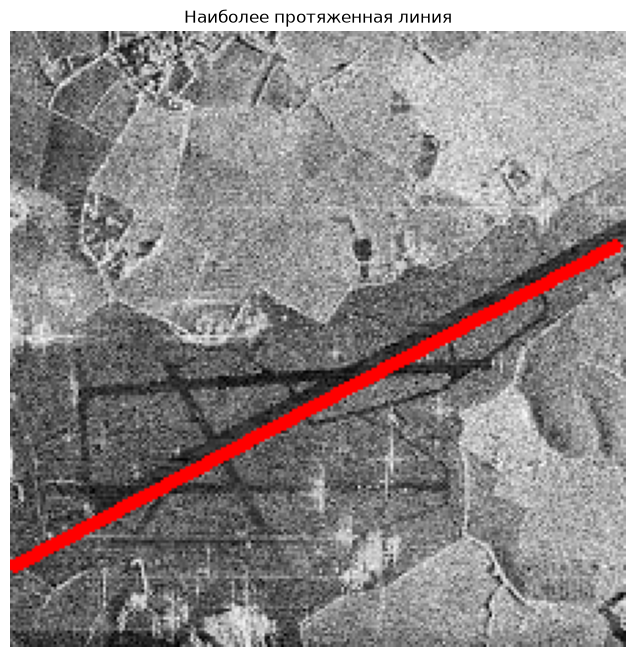

In [5]:
max_length = 0
longest_line = None

for x1, y1, x2, y2 in lines.reshape(-1, 4):
    length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)

    if length > max_length:
        max_length = length
        longest_line = (x1, y1, x2, y2)

result = image_sar3.copy()

if longest_line is not None:
    x1, y1, x2, y2 = longest_line
    cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 3)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Наиболее протяженная линия')
plt.axis('off')
plt.show()

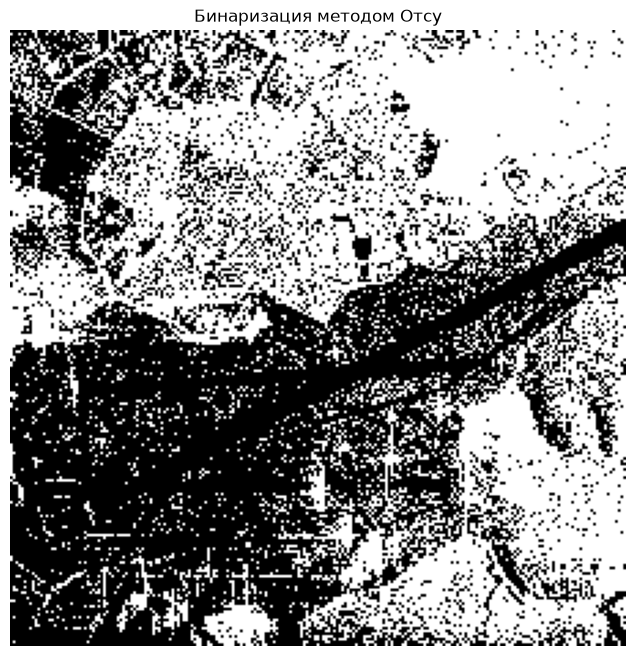

In [6]:
_, binary_otsu = cv2.threshold(
    image_sar3_gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(8, 8))
plt.imshow(binary_otsu, cmap='gray')
plt.title('Бинаризация методом Отсу')
plt.axis('off')
plt.show()

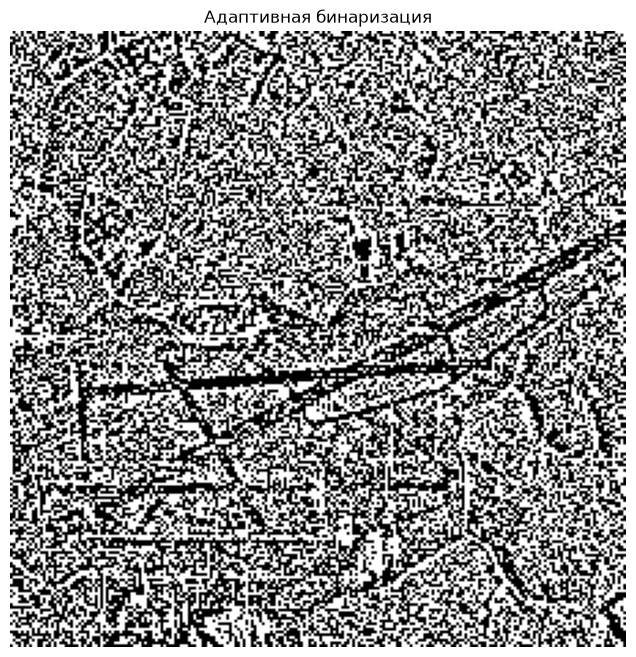

In [7]:
binary_adaptive = cv2.adaptiveThreshold(
    image_sar3_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.figure(figsize=(8, 8))
plt.imshow(binary_adaptive, cmap='gray')
plt.title('Адаптивная бинаризация')
plt.axis('off')
plt.show()

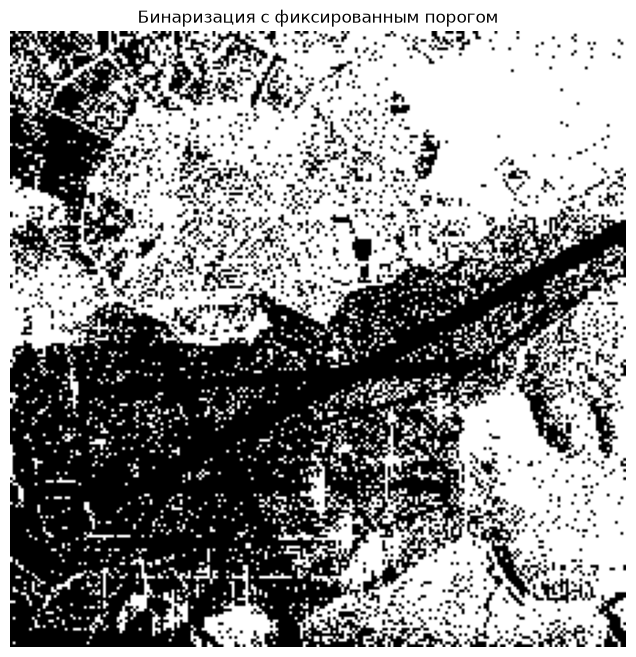

In [8]:
_, binary_simple = cv2.threshold(
    image_sar3_gray,
    127,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(8, 8))
plt.imshow(binary_simple, cmap='gray')
plt.title('Бинаризация с фиксированным порогом')
plt.axis('off')
plt.show()

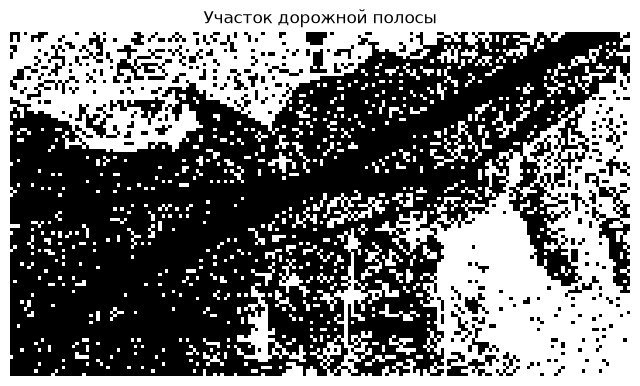

In [9]:
road_section = binary_otsu[80:180, 40:220]

plt.figure(figsize=(8, 5))
plt.imshow(road_section, cmap='gray')
plt.title('Участок дорожной полосы')
plt.axis('off')
plt.show()